# Pre-registered 16x/32x transplant check (exploratory)
Reads `results/transplant/tx4de_model_measures.csv` and `tx4de_summary.json` (`zoo.transplant_check_analysis`).
Figure only (`reports/figures/transplant_check.png`). S = sum of the 8 single-block recovered fractions; B = mean
recovered fraction over the whole-model blends at a = 0.1 ... 0.9. Prediction: later crossing -> lower S and B.

In [1]:
from pathlib import Path
import json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
T = ROOT / "results/transplant"
m = pd.read_csv(T / "tx4de_model_measures.csv")
res = json.loads((T / "tx4de_summary.json").read_text())
DOSES = [1, 8, 16, 32, 64]
COL = {1: "#2a78d6", 8: "#eb6834", 16: "#eda100", 32: "#e87ba4", 64: "#1baf7a"}
INK, MUTED, GRID, CT = "#2b2b2a", "#8a8980", "#e4e3df", "#c2410c"
plt.rcParams.update({"font.size": 8.5, "axes.edgecolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
                     "grid.linewidth": 0.6})
for key in ("S_single_block_sum", "B_matched_blend_mean_f"):
    r = res[key]
    print(key, "seeds pass", r["n_seeds_pass"], "overall", r["pass_overall"])
    for k, v in r["per_seed"].items():
        print(" ", k, v["n_new_concordant"], "/", v["n_new_pairs"], "pass" if v["pass"] else "FAIL", v["order_low_to_high"])

S_single_block_sum seeds pass 3 overall False
  0 6 / 6 pass ['8x', '16x', '32x', '64x', '1x']
  1 6 / 6 pass ['8x', '16x', '32x', '1x', '64x']
  2 2 / 4 FAIL ['8x', '1x', '16x', '32x', '64x']
  3 5 / 6 FAIL ['8x', '16x', '64x', '1x', '32x']
  4 6 / 6 pass ['8x', '16x', '32x', '64x', '1x']
B_matched_blend_mean_f seeds pass 0 overall False
  0 5 / 6 FAIL ['8x', '1x', '16x', '32x', '64x']
  1 5 / 6 FAIL ['8x', '1x', '16x', '32x', '64x']
  2 2 / 4 FAIL ['8x', '1x', '16x', '32x', '64x']
  3 5 / 6 FAIL ['8x', '1x', '16x', '32x', '64x']
  4 5 / 6 FAIL ['8x', '1x', '16x', '32x', '64x']


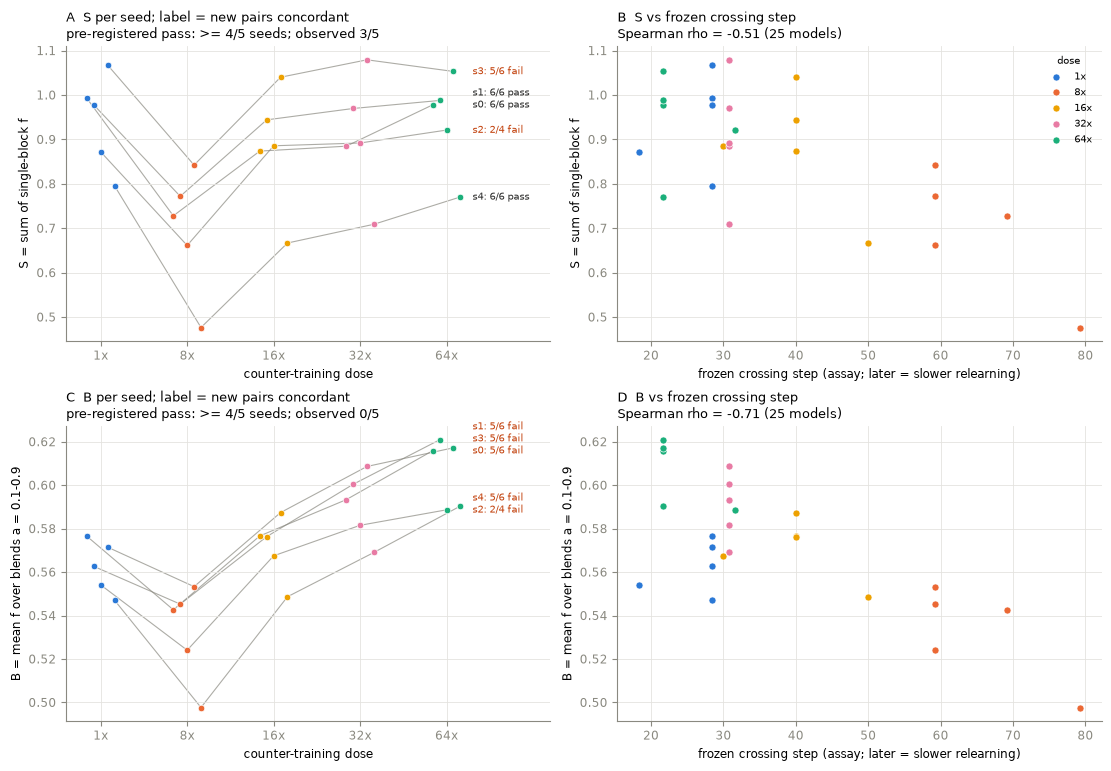

In [2]:
fig, ax = plt.subplots(2, 2, figsize=(11, 7.6), constrained_layout=True)
jit = {0: -0.16, 1: -0.08, 2: 0.0, 3: 0.08, 4: 0.16}
for row, (col, key, lab) in enumerate((("S", "S_single_block_sum", "S = sum of single-block f"),
                                       ("B", "B_matched_blend_mean_f", "B = mean f over blends a = 0.1-0.9"))):
    L, Rr = ax[row]
    # left: per seed, by dose; pass/fail per seed at the right end
    for k, g in m.groupby("seed"):
        g = g.set_index("dose").loc[DOSES]
        L.plot([i + jit[k] for i in range(5)], g[col], color=MUTED, lw=0.8, alpha=0.7, zorder=1)
        for i, d in enumerate(DOSES):
            L.scatter(i + jit[k], g.loc[d, col], color=COL[d], s=22, edgecolor="white", linewidth=0.5, zorder=3)
    # seed labels at the right end, pushed apart so they do not overlap
    ys = m[m.dose == 64].set_index("seed")[col].sort_values()
    gap = 0.045 * (m[col].max() - m[col].min())
    pos, last = {}, -np.inf
    for k, y in ys.items():
        pos[k] = max(y, last + gap); last = pos[k]
    for k, y in pos.items():
        ps = res[key]["per_seed"][str(k)]
        L.text(4.3, y, f"s{k}: {ps['n_new_concordant']}/{ps['n_new_pairs']} {'pass' if ps['pass'] else 'fail'}",
               fontsize=7.5, va="center", color=INK if ps["pass"] else CT)
    L.set_xticks(range(5), [f"{d}x" for d in DOSES]); L.set_xlim(-0.4, 5.2)
    L.set_ylabel(lab); L.set_xlabel("counter-training dose")
    L.set_title(f"{'AC'[row]}  {col} per seed; label = new pairs concordant\n"
                f"pre-registered pass: >= 4/5 seeds; observed {res[key]['n_seeds_pass']}/5", loc="left", fontsize=9)
    # right: against the frozen crossing step (median of 3 assay seeds), every model
    for d in DOSES:
        g = m[m.dose == d]
        Rr.scatter(g.crossing + (DOSES.index(d) - 2) * 0.8, g[col], color=COL[d], s=26, edgecolor="white",
                   linewidth=0.5, label=f"{d}x", zorder=3)
    Rr.set_xlabel("frozen crossing step (assay; later = slower relearning)"); Rr.set_ylabel(lab)
    Rr.set_title(f"{'BD'[row]}  {col} vs frozen crossing step\n"
                 f"Spearman rho = {res[key]['rho_vs_crossing_all']:.2f} (25 models)", loc="left", fontsize=9)
    if row == 0:
        Rr.legend(frameon=False, fontsize=7.5, title="dose", title_fontsize=7.5, loc="upper right")
fig.savefig(ROOT / "reports/figures/transplant_check.png", dpi=150)